**BOSCHI NATHAN - M2 MIAGE**

# Devoir maison #1 - Introduction and Learnability

sujet : [./HW1.pdf](./HW1.pdf)

## Objectif
Le but de cet exercice est d'illustrer la différence entre le cadre PAC et le cadre Agnostic PAC.

On considère une classe d'hypothèses composée de classifieurs à seuil sur l'intervalle [0,1]. Un algorithme est implémenté puis testé dans deux situations :
- cadre réalisable (sans bruit) ;
- cadre agnostique (avec bruit sur les labels).

Les résultats sont ensuite analysés afin de comparer les deux cadres théoriques.

In [56]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

## Génération des données

Le sujet considère un seuil inconnu theta.

Pour les expériences, j'ai choisi :

theta = 0.6

Les exemples sont tirés uniformément dans l'intervalle [0,1].

La règle de classification est :
```
f(x) = 1 si x > theta
f(x) = 0 sinon
```
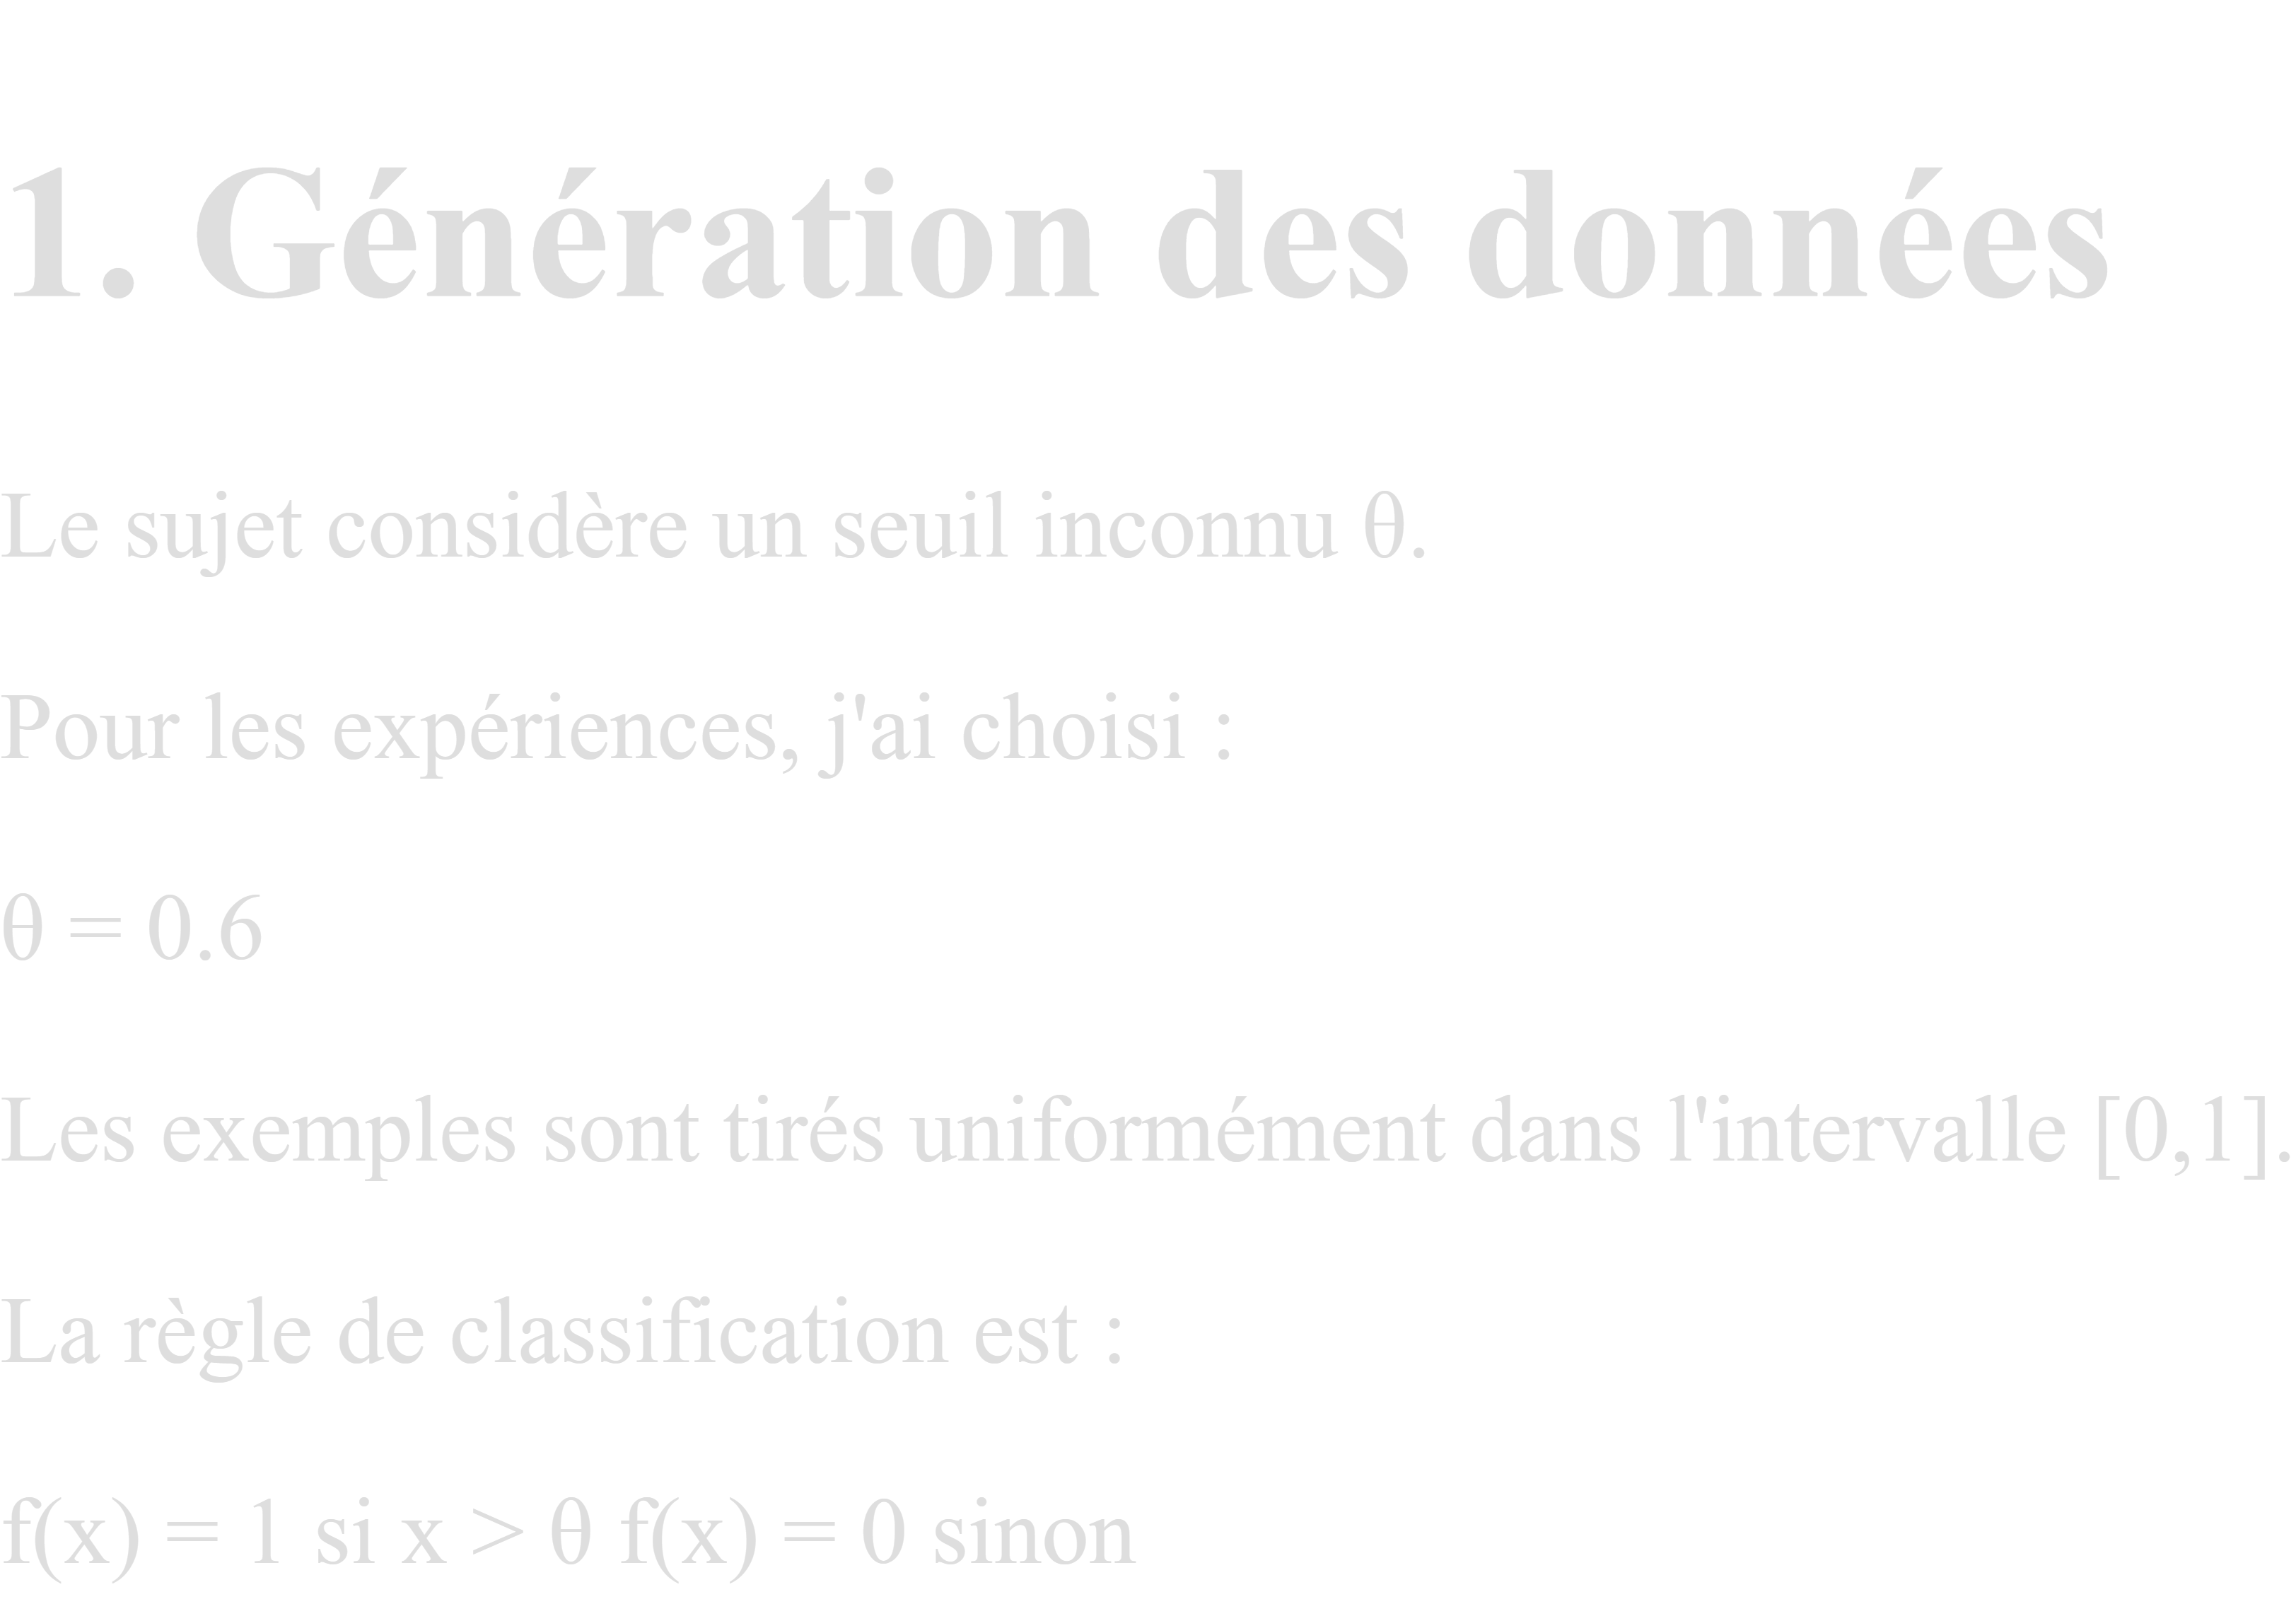

In [57]:
theta = 0.6

def generate_data(m, theta, noise_rate=0):

    X = np.random.uniform(0, 1, m)
    y = (X > theta).astype(int)

    if noise_rate > 0:
        flips = np.random.rand(m) < noise_rate
        y[flips] = 1 - y[flips]

    return X, y

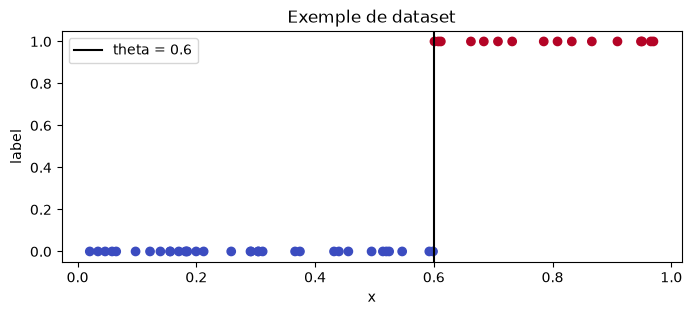

In [58]:
X_vis, y_vis = generate_data(50, theta) # On génère un petit dataset de 50 exemples pour visualiser les labels.

plt.figure(figsize=(8,3))
plt.scatter(X_vis, y_vis, c=y_vis, cmap="coolwarm")
plt.axvline(theta, linestyle="-", color="black",
            label=f"theta = {theta}")

plt.xlabel("x")
plt.ylabel("label")
plt.title("Exemple de dataset")
plt.legend()
plt.show()

## Implémentation de l'ERM

L'idée est de tester tous les seuils possibles situés entre deux observations successives.

Pour chaque seuil :
- on calcule l'erreur empirique ;
- on conserve celui qui minimise cette erreur.

Ce seuil correspond à l'hypothèse la plus plausible ERM.

In [59]:
def predict(X, threshold):
    return (X > threshold).astype(int)


def empirical_error(X, y, threshold):
    predictions = predict(X, threshold)
    return np.mean(predictions != y)


def erm_threshold(X, y):

    X_sorted = np.sort(X)

    possibilities = [0]

    for i in range(len(X_sorted)-1):
        possibilities.append(
            (X_sorted[i] + X_sorted[i+1]) / 2
        )

    possibilities.append(1)

    best_threshold = possibilities[0]
    best_error = empirical_error(X, y, best_threshold)

    for threshold in possibilities:

        error = empirical_error(X, y, threshold)

        if error < best_error:
            best_error = error
            best_threshold = threshold

    return best_threshold, best_error

## Comparaison entre erreur empirique et erreur vraie

In [60]:
sample_sizes = [5, 10, 20, 50, 100, 200]

results = []

for m in sample_sizes:

    X_train, y_train = generate_data(m, theta)

    threshold_hat, train_error = erm_threshold(X_train, y_train)

    X_test, y_test = generate_data(10000, theta)

    true_error = empirical_error(
        X_test,
        y_test,
        threshold_hat
    )

    results.append(
        [m, threshold_hat, train_error, true_error]
    )

for r in results:
    print(
        f"m={r[0]:3d} | "
        f"seuil={r[1]:.4f} | "
        f"err. empirique={r[2]:.4f} | "
        f"err. vraie={r[3]:.4f}"
    )

m=  5 | seuil=0.6865 | err. empirique=0.0000 | err. vraie=0.0858
m= 10 | seuil=0.6792 | err. empirique=0.0000 | err. vraie=0.0766
m= 20 | seuil=0.6171 | err. empirique=0.0000 | err. vraie=0.0203
m= 50 | seuil=0.6271 | err. empirique=0.0000 | err. vraie=0.0279
m=100 | seuil=0.5954 | err. empirique=0.0000 | err. vraie=0.0042
m=200 | seuil=0.6002 | err. empirique=0.0000 | err. vraie=0.0001


### Commentaire

Dans la plupart des essais, l'erreur empirique devient nulle car le problème est réalisable.

On remarque également que lorsque le nombre d'exemples augmente, le seuil obtenu se rapproche du seuil réel et l'erreur vraie diminue.

## Vérification du PAC Learning

On estime :

Pr(L(h) > epsilon)

avec :
epsilon = 0.05

Chaque expérience est répétée 1000 fois.

In [61]:
epsilon = 0.05
repetitions = 1000

pac_probabilities = []

for m in sample_sizes:

    failures = 0

    for _ in range(repetitions):

        X_train, y_train = generate_data(m, theta)

        h, _ = erm_threshold(X_train, y_train)

        X_test, y_test = generate_data(10000, theta)

        true_error = empirical_error(
            X_test,
            y_test,
            h
        )

        if true_error > epsilon:
            failures += 1

    pac_probabilities.append(
        failures / repetitions
    )

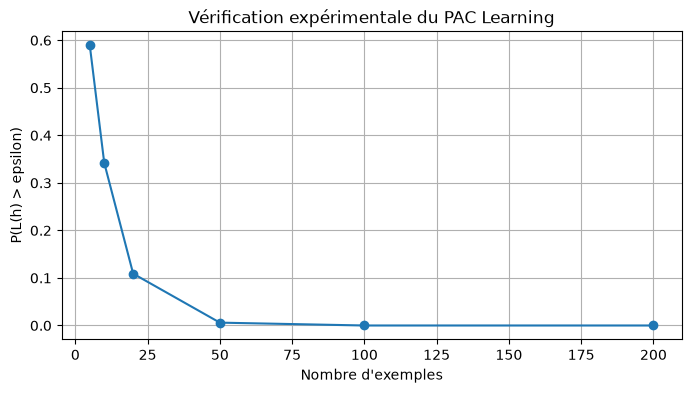

In [62]:
plt.figure(figsize=(8,4))

plt.plot(
    sample_sizes,
    pac_probabilities,
    marker="o"
)

plt.xlabel("Nombre d'exemples")
plt.ylabel("P(L(h) > epsilon)")
plt.title("Vérification expérimentale du PAC Learning")

plt.grid(True)
plt.show()

### Analyse

La probabilité que l'erreur vraie dépasse epsilon
diminue lorsque la taille de l'échantillon augmente.

Ce résultat est conforme à la définition du PAC Learning : avec suffisamment de données, il devient très probable d'obtenir une hypothèse proche de la cible.

## Passage au cadre Agnostic PAC

On introduit maintenant un bruit sur les labels.

Chaque label a une probabilité η = 0.1 d'être inversé.

In [63]:
noise_rate = 0.10

mean_errors = []

for m in sample_sizes:

    errors = []

    for _ in range(repetitions):

        X_train, y_train = generate_data(
            m,
            theta,
            noise_rate
        )

        h, train_err = erm_threshold(
            X_train,
            y_train
        )

        X_test, y_test = generate_data(
            10000,
            theta,
            noise_rate
        )

        test_err = empirical_error(
            X_test,
            y_test,
            h
        )

        errors.append(test_err)

    mean_errors.append(
        np.mean(errors)
    )

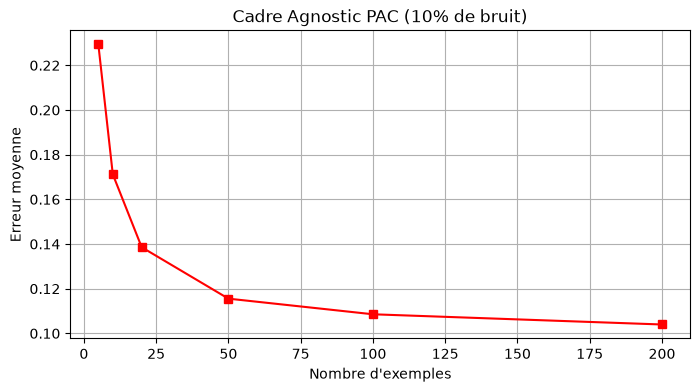

In [64]:
plt.figure(figsize=(8,4))

plt.plot(
    sample_sizes,
    mean_errors,
    marker="s",
    color="red"
)

plt.xlabel("Nombre d'exemples")
plt.ylabel("Erreur moyenne")

plt.title(
    "Cadre Agnostic PAC (10% de bruit)"
)

plt.grid(True)
plt.show()

## Discussion

### L'erreur empirique peut-elle encore atteindre zéro ?

Dans le cadre agnostique, cela devient rare. Comme certains labels sont modifiés aléatoirement, il n'existe généralement aucun seuil capable de classifier parfaitement tous les exemples.

### Est-ce que plus de données aide encore ?

Oui. Même si le bruit empêche d'atteindre une erreur nulle, augmenter la taille de l'échantillon permet d'obtenir une hypothèse plus stable et une meilleure estimation du vrai seuil.

### Lien avec la théorie

Dans le cadre PAC réalisable, la fonction cible appartient à la classe d'hypothèses étudiée. L'ERM peut donc trouver une solution parfaite sur les données d'entraînement.

Dans le cadre Agnostic PAC, cette hypothèse n'est plus vérifiée puisque le bruit rend le problème non parfaitement réalisable. L'objectif devient alors de trouver l'hypothèse qui minimise l'erreur parmi toutes celles disponibles.